In [1]:
# =========================================================
# RPDA8412 RESEARCH PROJECT
# NOTEBOOK 07: BASELINE FORECASTING MODEL
# =========================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FINAL_DIR = PROJECT_ROOT / "data" / "final"
MODELS_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "tables"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    FINAL_DIR / "model_features_20d_provisional.csv",
    parse_dates=["Date"]
)

df = df.sort_values("Date").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())

Dataset shape: (3944, 17)
First date: 2010-03-31 00:00:00
Last date: 2025-12-02 00:00:00


In [2]:
# =========================================================
# BASELINE FEATURES
# =========================================================

MARKET_FEATURES = [
    "Return_Lag1",
    "Absolute_Return",
    "RV_Historical_5D",
    "RV_Historical_10D",
    "RV_Historical_20D",
    "RV_Historical_60D",
    "RV_20D_Lag1"
]

TARGET = "RV_Future_20D"

print("Predictors:", len(MARKET_FEATURES))
print("Target:", TARGET)

assert df[MARKET_FEATURES + [TARGET]].notna().all().all()

Predictors: 7
Target: RV_Future_20D


In [3]:
# =========================================================
# CHRONOLOGICAL SPLITTING
# =========================================================

train = df[
    df["Date"] < "2020-01-01"
].copy()

validation = df[
    (df["Date"] >= "2020-01-01") &
    (df["Date"] < "2023-01-01")
].copy()

test = df[
    df["Date"] >= "2023-01-01"
].copy()

print("Training observations:", len(train))
print("Validation observations:", len(validation))
print("Testing observations:", len(test))

print("\nTraining dates:")
print(train["Date"].min(), "to", train["Date"].max())

print("\nValidation dates:")
print(validation["Date"].min(), "to", validation["Date"].max())

print("\nTesting dates:")
print(test["Date"].min(), "to", test["Date"].max())

Training observations: 2456
Validation observations: 756
Testing observations: 732

Training dates:
2010-03-31 00:00:00 to 2019-12-31 00:00:00

Validation dates:
2020-01-02 00:00:00 to 2022-12-30 00:00:00

Testing dates:
2023-01-03 00:00:00 to 2025-12-02 00:00:00


In [4]:
# =========================================================
# PURGE OVERLAPPING TARGET WINDOWS
# =========================================================

HORIZON = 20

def purge_training_data(
    training_data,
    full_data,
    next_period_start,
    horizon=20
):
    """
    Retain training observations only when their
    future-volatility target is fully observable
    before the next evaluation period begins.
    """

    next_start_position = full_data.index[
        full_data["Date"] >= next_period_start
    ][0]

    # Last allowable training row must have its
    # full target window before the evaluation period
    last_allowed_position = next_start_position - horizon - 1

    return training_data.loc[
        training_data.index <= last_allowed_position
    ].copy()


train_purged = purge_training_data(
    train,
    df,
    pd.Timestamp("2020-01-01"),
    HORIZON
)

validation_purged = purge_training_data(
    validation,
    df,
    pd.Timestamp("2023-01-01"),
    HORIZON
)

print("Original training observations:", len(train))
print("Purged training observations:", len(train_purged))

print("\nOriginal validation observations:", len(validation))
print("Purged validation observations:", len(validation_purged))

print("\nLast purged training date:")
print(train_purged["Date"].max())

print("\nLast purged validation date:")
print(validation_purged["Date"].max())

Original training observations: 2456
Purged training observations: 2436

Original validation observations: 756
Purged validation observations: 736

Last purged training date:
2019-12-02 00:00:00

Last purged validation date:
2022-12-01 00:00:00


In [5]:
# =========================================================
# TRAIN LINEAR REGRESSION BASELINE
# =========================================================

X_train = train_purged[MARKET_FEATURES]
y_train = train_purged[TARGET]

X_validation = validation[MARKET_FEATURES]
y_validation = validation[TARGET]

model = LinearRegression()

model.fit(
    X_train,
    y_train
)

validation_predictions = model.predict(
    X_validation
)

# Volatility cannot be negative
validation_predictions = np.maximum(
    validation_predictions,
    0
)

print("Linear Regression model trained successfully!")
print("Training observations:", len(X_train))
print("Validation observations:", len(X_validation))

Linear Regression model trained successfully!
Training observations: 2436
Validation observations: 756


In [6]:
# =========================================================
# VALIDATION PERFORMANCE
# =========================================================

def evaluate_forecast(y_true, y_pred):

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    epsilon = 1e-4

    safe_mape = np.mean(
        np.abs(
            (np.asarray(y_true) - np.asarray(y_pred)) /
            np.maximum(np.abs(np.asarray(y_true)), epsilon)
        )
    ) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "Safe_MAPE": safe_mape
    }


validation_metrics = evaluate_forecast(
    y_validation,
    validation_predictions
)

print("=" * 60)
print("LINEAR REGRESSION VALIDATION RESULTS")
print("=" * 60)

for metric, value in validation_metrics.items():
    print(f"{metric}: {value:.6f}")

LINEAR REGRESSION VALIDATION RESULTS
RMSE: 0.035895
MAE: 0.018616
Safe_MAPE: 27.730350


In [7]:
# =========================================================
# SAVE BASELINE VALIDATION RESULTS
# =========================================================

validation_results = pd.DataFrame({
    "Date": validation["Date"].values,
    "Actual": y_validation.values,
    "Predicted": validation_predictions
})

validation_results.to_csv(
    TABLES_DIR / "linear_regression_validation_predictions.csv",
    index=False
)

metrics_df = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Feature_Set": "Market Only",
        "Period": "Validation",
        **validation_metrics
    }
])

metrics_df.to_csv(
    TABLES_DIR / "linear_regression_validation_metrics.csv",
    index=False
)

print("Validation predictions saved!")
print("Validation metrics saved!")

Validation predictions saved!
Validation metrics saved!


In [8]:
# =========================================================
# STEP 8: HISTORICAL VOLATILITY PERSISTENCE BENCHMARK
# =========================================================

print("=" * 60)
print("HISTORICAL VOLATILITY PERSISTENCE BENCHMARK")
print("=" * 60)

# Persistence forecast:
# Future 20-day volatility = current historical 20-day volatility

persistence_predictions = validation[
    "RV_Historical_20D"
].to_numpy()

persistence_actual = validation[
    "RV_Future_20D"
].to_numpy()

print("Validation observations:", len(validation))

print("\nFirst 5 predictions:")
print(persistence_predictions[:5])

print("\nFirst 5 actual values:")
print(persistence_actual[:5])

HISTORICAL VOLATILITY PERSISTENCE BENCHMARK
Validation observations: 756

First 5 predictions:
[0.0212431  0.02148789 0.02172378 0.01992731 0.02027262]

First 5 actual values:
[0.03251311 0.03254469 0.03560635 0.03721691 0.03704329]


In [9]:
# =========================================================
# STEP 9: EVALUATE PERSISTENCE BENCHMARK
# =========================================================

persistence_metrics = evaluate_forecast(
    persistence_actual,
    persistence_predictions
)

print("=" * 60)
print("PERSISTENCE BENCHMARK VALIDATION RESULTS")
print("=" * 60)

for metric, value in persistence_metrics.items():
    print(f"{metric}: {value:.6f}")

PERSISTENCE BENCHMARK VALIDATION RESULTS
RMSE: 0.043013
MAE: 0.023945
Safe_MAPE: 37.751981


In [10]:
# =========================================================
# STEP 10: BASELINE MODEL COMPARISON
# =========================================================

comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        **validation_metrics
    },
    {
        "Model": "Persistence",
        **persistence_metrics
    }
])

comparison = comparison.sort_values(
    "RMSE"
).reset_index(drop=True)

print("=" * 60)
print("BASELINE MODEL COMPARISON")
print("=" * 60)

display(comparison.round(6))

comparison.to_csv(
    TABLES_DIR / "baseline_model_comparison.csv",
    index=False
)

print("\nComparison saved successfully!")

BASELINE MODEL COMPARISON


,Model,RMSE,MAE,Safe_MAPE
0,Linear Regression,0.035895,0.018616,27.730350
1,Persistence,0.043013,0.023945,37.751981



Comparison saved successfully!


In [11]:
# =========================================================
# STEP 11: IMPROVEMENT OVER PERSISTENCE
# =========================================================

rmse_improvement = (
    (
        persistence_metrics["RMSE"]
        - validation_metrics["RMSE"]
    )
    / persistence_metrics["RMSE"]
) * 100

mae_improvement = (
    (
        persistence_metrics["MAE"]
        - validation_metrics["MAE"]
    )
    / persistence_metrics["MAE"]
) * 100

print("=" * 60)
print("LINEAR REGRESSION VS PERSISTENCE")
print("=" * 60)

print(
    f"RMSE improvement: {rmse_improvement:.2f}%"
)

print(
    f"MAE improvement: {mae_improvement:.2f}%"
)

LINEAR REGRESSION VS PERSISTENCE
RMSE improvement: 16.55%
MAE improvement: 22.26%


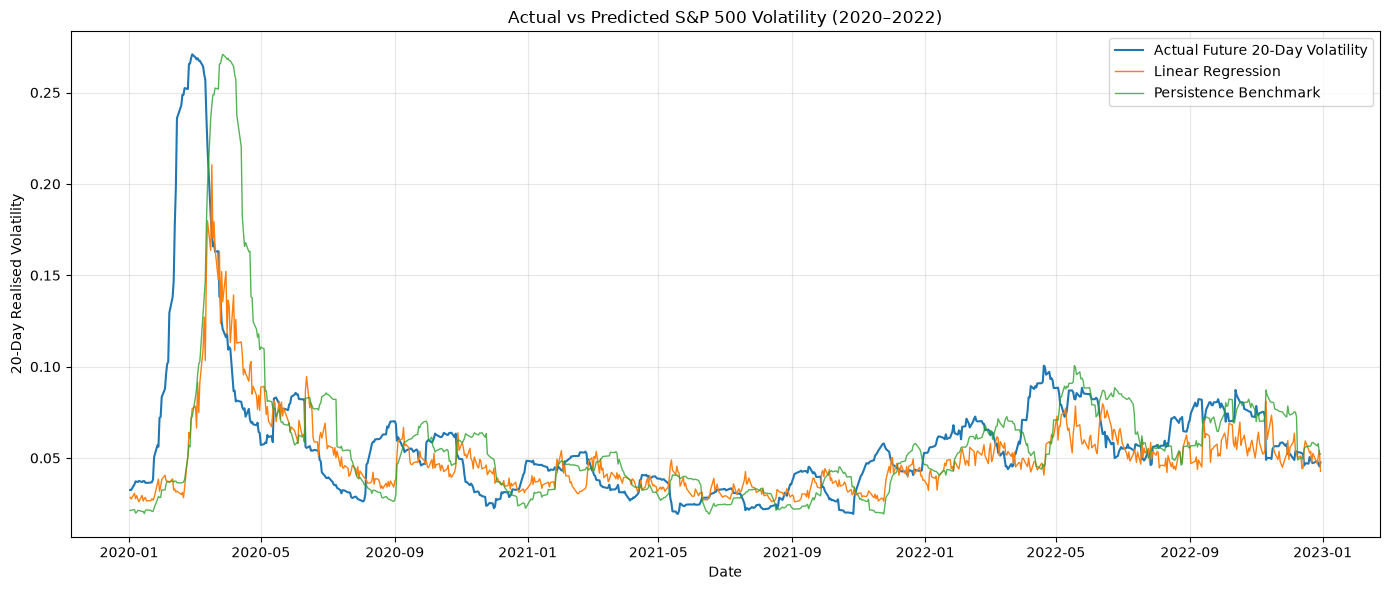

In [12]:
# =========================================================
# STEP 12: VISUALISE BASELINE FORECASTS
# =========================================================

import matplotlib.pyplot as plt

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(14, 6))

plt.plot(
    validation["Date"],
    persistence_actual,
    label="Actual Future 20-Day Volatility",
    linewidth=1.5
)

plt.plot(
    validation["Date"],
    validation_predictions,
    label="Linear Regression",
    linewidth=1
)

plt.plot(
    validation["Date"],
    persistence_predictions,
    label="Persistence Benchmark",
    linewidth=1,
    alpha=0.8
)

plt.title(
    "Actual vs Predicted S&P 500 Volatility (2020–2022)"
)

plt.xlabel("Date")
plt.ylabel("20-Day Realised Volatility")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()